# Assignment 3

## MCMC and 2D Ising Model

In [21]:
import json
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

In [26]:
J = 1.0
KB = 1.0
N = 20
SEED = 200101723

### Problem A

In [27]:
@njit
def flip_energy(spins, i, j):
    n = spins.shape[0]
    neighbors = (
        spins[(i - 1) % n, j] +
        spins[(i + 1) % n, j] +
        spins[i, (j - 1) % n] +
        spins[i, (j + 1) % n]
    )
    return 2 * J * spins[i, j] * neighbors

@njit
def metropolis_step(spins, temperature, rng):
    i, j = rng.integers(0, spins.shape[0], size=2)
    delta_energy = flip_energy(spins, i, j)

    if delta_energy <= 0 or rng.random() < np.exp(-delta_energy / (KB * temperature)):
        spins[i, j] *= -1
        return 1

    return 0

@njit
def advance_ising(spins, temperature, sweeps, rng):
    n = spins.shape[0]
    magnetization = np.empty(sweeps + 1)
    magnetization[0] = spins.mean()
    accepted = 0

    for sweep in range(1, sweeps + 1):
        for _ in range(n * n):
            accepted += metropolis_step(spins, temperature, rng)

        magnetization[sweep] = spins.mean()

    return magnetization, accepted

def run_ising(temperature, n, sweeps, seed, initial="up"):
    rng = np.random.default_rng(seed)

    if initial == "up":
        spins = np.ones((n, n), dtype=int)
    elif initial == "random":
        spins = rng.choice(np.array([-1, 1]), size=(n, n))
    else:
        raise ValueError("Initial configuration must be 'up' or 'random'")

    magnetization, accepted = advance_ising(spins, temperature, sweeps, rng)

    return spins, magnetization, accepted / (sweeps * n * n)

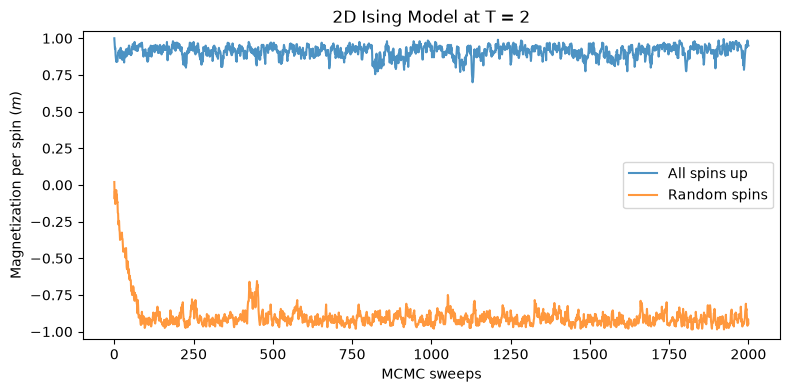

In [47]:
T = 2.0
SWEEPS = 2000

_, m_up, _ = run_ising(T, N, SWEEPS, SEED, initial="up")
_, m_random, _ = run_ising(T, N, SWEEPS, SEED + 1, initial="random")

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(m_up, label="All spins up", alpha=0.8)
ax.plot(m_random, label="Random spins", alpha=0.8)

ax.set(
    xlabel="MCMC sweeps",
    ylabel="Magnetization per spin $(m)$",
    title="2D Ising Model at T = 2",
    ylim=(-1.05, 1.05)
)
ax.legend()
plt.show()

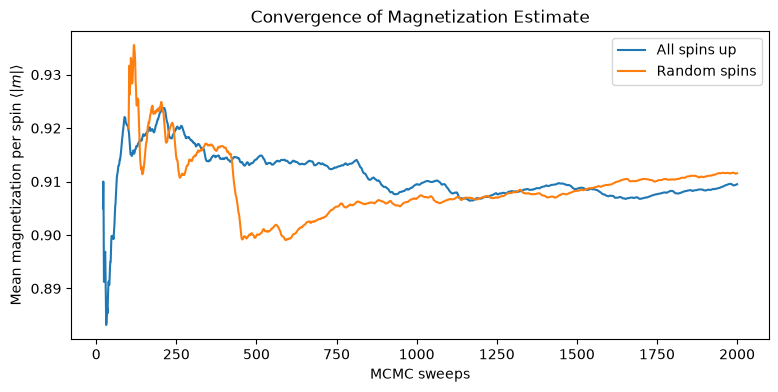

In [48]:
BURNIN_UP = 20
BURNIN_RANDOM = 100

def running_average(m_values, burnin):
    samples = np.abs(m_values[burnin + 1:])
    return np.cumsum(samples) / np.arange(1, len(samples) + 1)

avg_up = running_average(m_up, BURNIN_UP)
avg_random = running_average(m_random, BURNIN_RANDOM)

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(np.arange(BURNIN_UP + 1, SWEEPS + 1), avg_up,
        label="All spins up")
ax.plot(np.arange(BURNIN_RANDOM + 1, SWEEPS + 1), avg_random,
        label="Random spins")

ax.set(
    xlabel="MCMC sweeps",
    ylabel=r"Mean magnetization per spin $\langle|m|\rangle$",
    title="Convergence of Magnetization Estimate"
)
ax.legend()
plt.show()